# 03 · First supervised model: learn to rank candidate services

**Question:** Can a fixed Random Forest combine service-change features
more effectively than the two heuristic rules on held-out scenarios?

We preserve the original baselines and raw data. This notebook reruns the
five grouped folds specified in [ML_PROTOCOL.md](../docs/ML_PROTOCOL.md).
The dataset has already been explored, so this is exploratory within-system
cross-validation, not a pristine final test or cross-system result.

In [1]:
from pathlib import Path
import sys
import os
import json
ROOT = Path.cwd()
if not (ROOT / 'pyproject.toml').is_file():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.mplconfig'))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from rca.data import list_cases, load_case
from rca.features import FEATURE_COLUMNS, extract_service_features
from rca.supervised import run_experiment, OUTPUT_DIR
from rca.ml_report import overall_table, plot_grouped_comparison, build_report

## 1. Features describe behavior, not names

Each candidate service gets 48 numbers: six features for each of eight
measurement types. They describe availability, signed standardized mean
change, relative mean change, variability change, constant normal behavior,
and a zero-to-nonzero onset. Missing measurements use an explicit
availability flag; they are not filled across the fault boundary.

Names identify rows for reporting only. Labels are stored separately and
sklearn receives only the numeric feature matrix. These summaries do not
preserve the full time-series order: this is a tabular learned baseline,
not yet a temporal encoder or GNN.

In [2]:
example = list_cases()[0]
measurements, injection, root, _, _ = load_case(example)
example_features = extract_service_features(measurements, injection)
print('One row per candidate; numeric features:', len(FEATURE_COLUMNS))
display(example_features[[name for name in FEATURE_COLUMNS if name.startswith('cpu__')]])

One row per candidate; numeric features: 48


,cpu__available,cpu__signed_log_shift,cpu__relative_shift,cpu__log_std_ratio,cpu__normal_constant,cpu__zero_to_nonzero
service,,,,,,
PassthroughCluster,0.0,0.000000,0.000000,0.000000,0.0,0.0
adservice,1.0,3.819000,0.962891,1.721976,0.0,0.0
cartservice,1.0,-0.232647,-0.016870,-0.089846,0.0,0.0
checkoutservice,1.0,-0.052688,-0.002671,0.075386,0.0,0.0
currencyservice,1.0,-0.077197,-0.002555,0.004538,0.0,0.0
emailservice,1.0,-0.037469,-0.001345,-0.009583,0.0,0.0
frontend,1.0,-0.178885,-0.006274,0.016756,0.0,0.0
frontend-external,0.0,0.000000,0.000000,0.000000,0.0,0.0
main,1.0,-0.136077,-0.004489,-0.058567,0.0,0.0


## 2. Split scenarios before training

A scenario is a root-service / fault-type combination. All its repeated
incidents stay together. We use five GroupKFold folds and expand each
training/test incident set into candidate rows only afterward. This keeps
both the same incident and repeated scenarios out of their model's training
set. Every evaluable incident is predicted once by a model that held it out.

## 3. Fit the fixed Random Forest

In each training fold, the candidate label is 1 for the injected root and
0 for other candidates. The forest learns combinations of feature values.
We use 300 trees, depth at most 6, minimum leaf size 3, balanced_subsample
class weights, seed 42, and one worker. No search or best-seed selection.

Class-1 predict_proba scores determine ranking; they are not calibrated
incident-level confidence. The configuration and split manifest are saved
**before** the first fit. Original heuristic rules are evaluated on the
same held-out incidents for a fair candidate/denominator comparison.

In [3]:
per_case, summary, fold_summary = run_experiment()
manifest = json.loads((OUTPUT_DIR / 'split_manifest.json').read_text())
split_rows = []
tested = []
for fold in manifest['folds']:
    assert not set(fold['train_case_ids']) & set(fold['test_case_ids'])
    assert not set(fold['train_groups']) & set(fold['test_groups'])
    tested.extend(fold['test_case_ids'])
    split_rows.append({'fold': fold['fold'], 'train_incidents': len(fold['train_case_ids']),
                       'test_incidents': len(fold['test_case_ids']), 'test_scenarios': len(fold['test_groups'])})
assert len(tested) == len(set(tested)) == manifest['n_evaluable']
display(pd.DataFrame(split_rows))
print('All incident and scenario isolation checks passed.')

Fold 1: trained on 98 incidents; predicted 25 held-out incidents.


Fold 2: trained on 98 incidents; predicted 25 held-out incidents.


Fold 3: trained on 98 incidents; predicted 25 held-out incidents.


Fold 4: trained on 99 incidents; predicted 24 held-out incidents.


Fold 5: trained on 99 incidents; predicted 24 held-out incidents.


         method  n_cases     AC@1     AC@3    AC@5    Avg@5
  random_forest      123 0.918699 0.959350 0.99187 0.960976
         zscore      123 0.504065 0.894309 0.95122 0.821138
zscore_nonconst      123 0.772358 0.918699 1.00000 0.907317


,fold,train_incidents,test_incidents,test_scenarios
0,1,98,25,5
1,2,98,25,5
2,3,98,25,5
3,4,99,24,5
4,5,99,24,5


All incident and scenario isolation checks passed.


## 4. Compare pooled held-out rankings and inspect variability

The primary table uses only the 123 evaluable incidents. We separately
retain a table for all 125 supplied incidents, where invalid recordings
count as misses. An empty ranking for an invalid recording is not a model
prediction. AC@k measures root localization per incident, not ordinary
binary accuracy over the many non-root service rows.

,method,n_cases,AC@1,AC@3,AC@5,Avg@5
6,Random Forest (OOF),123,91.87%,95.93%,99.19%,96.10%
18,Original z-score,123,50.41%,89.43%,95.12%,82.11%
30,Nonconstant z-score,123,77.24%,91.87%,100.00%,90.73%


,method,n_cases,n_evaluable,AC@1,AC@3,AC@5,Avg@5
0,random_forest,125,123,0.904,0.944,0.976,0.9456
12,zscore,125,123,0.496,0.880,0.936,0.8080
24,zscore_nonconst,125,123,0.760,0.904,0.984,0.8928


,method,fold,n_cases,AC@1,AC@3,Avg@5
0,random_forest,1,25,0.960000,1.000000,0.992000
1,random_forest,2,25,0.680000,0.800000,0.824000
2,random_forest,3,25,1.000000,1.000000,1.000000
3,random_forest,4,24,0.958333,1.000000,0.991667
4,random_forest,5,24,1.000000,1.000000,1.000000
5,zscore,1,25,0.400000,0.960000,0.840000
6,zscore,2,25,0.320000,0.560000,0.552000
7,zscore,3,25,0.600000,1.000000,0.896000
8,zscore,4,24,0.541667,0.958333,0.891667
9,zscore,5,24,0.666667,1.000000,0.933333


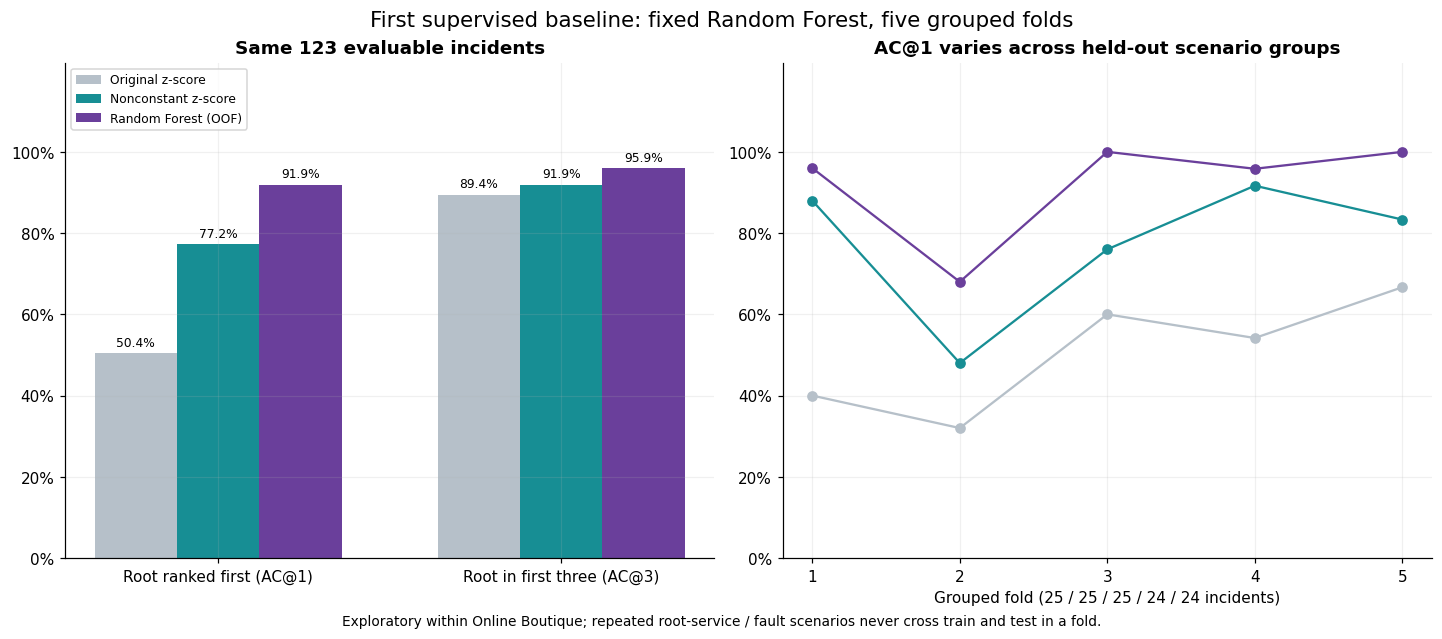

In [4]:
display(overall_table(summary))
display(summary.query("scope == 'overall' and evaluation_set == 'all_cases'")[
    ['method', 'n_cases', 'n_evaluable', 'AC@1', 'AC@3', 'AC@5', 'Avg@5']])
display(fold_summary[['method', 'fold', 'n_cases', 'AC@1', 'AC@3', 'Avg@5']])
figure = plot_grouped_comparison(summary, fold_summary)
plt.show()

## 5. What did the forest use, and where did it fail?

These importance values are impurity-based importance averaged over the
five training folds. They describe the fitted forests, not causal effects.
Correlated features and measurement-schema shortcuts can affect them.
We also list every held-out incident whose root was not ranked first.

In [5]:
importance = pd.read_csv(OUTPUT_DIR / 'feature_importance.csv')
display(importance.head(12))
failures = per_case.query("method == 'random_forest' and status == 'ok' and rank_of_true_root > 1")
display(failures[['case_id', 'fault_type', 'fold', 'true_root', 'rank_of_true_root']])
paired = pd.read_csv(OUTPUT_DIR / 'paired_case_comparison.csv')
gained = int((paired['rf_top1'] & ~paired['heuristic_top1']).sum())
lost = int((~paired['rf_top1'] & paired['heuristic_top1']).sum())
print('Top-one gains versus nonconstant heuristic:', gained, '| losses:', lost)
display(per_case.query("method == 'random_forest' and status != 'ok'")[['case_id', 'status', 'error']])

,feature,mean,std
0,cpu__log_std_ratio,0.145339,0.020446
1,cpu__signed_log_shift,0.128780,0.029034
2,cpu__relative_shift,0.111075,0.012063
3,mem__relative_shift,0.096879,0.015858
4,latency-90__relative_shift,0.086420,0.020209
5,latency-50__relative_shift,0.076110,0.021333
6,latency-90__signed_log_shift,0.062365,0.009993
7,mem__signed_log_shift,0.054278,0.013536
8,latency-50__signed_log_shift,0.047057,0.010370
9,latency-50__log_std_ratio,0.038190,0.006441


,case_id,fault_type,fold,true_root,rank_of_true_root
131,re1ob_cartservice_loss_4,loss,2,cartservice,2.0
197,re1ob_checkoutservice_loss_1,loss,2,checkoutservice,3.0
200,re1ob_checkoutservice_loss_2,loss,2,checkoutservice,2.0
251,re1ob_currencyservice_delay_4,delay,1,currencyservice,2.0
329,re1ob_productcatalogservice_delay_5,delay,4,productcatalogservice,2.0
347,re1ob_productcatalogservice_loss_1,loss,2,productcatalogservice,4.0
350,re1ob_productcatalogservice_loss_2,loss,2,productcatalogservice,5.0
353,re1ob_productcatalogservice_loss_3,loss,2,productcatalogservice,4.0
356,re1ob_productcatalogservice_loss_4,loss,2,productcatalogservice,6.0
359,re1ob_productcatalogservice_loss_5,loss,2,productcatalogservice,4.0


Top-one gains versus nonconstant heuristic: 19 | losses: 1


,case_id,status,error
272,re1ob_currencyservice_loss_1,invalid_window,Feature extraction needs >=2 normal and >=1 an...
308,re1ob_productcatalogservice_cpu_3,invalid_window,Feature extraction needs >=2 normal and >=1 an...


## 6. Interpretation and next experiment

The forest learns from labeled incidents and makes held-out predictions;
its performance is now an ML baseline. This does not establish performance
on a new application or production workload. The data was already explored,
there are only 25 scenario groups, and feature availability may indirectly
reveal service roles. Scores still use complete post-injection windows.

Keep both improvements and regressions visible. Next, reserve genuinely
new data and study feature/recording shortcuts before choosing a more
complex temporal or graph model. An application dependency graph has not
been built and no new fault injection was run.

In [6]:
report = build_report()
print('Saved docs/SUPERVISED_BASELINE.md, comparison figure, failures and fold evidence.')

Saved docs/SUPERVISED_BASELINE.md, comparison figure, failures and fold evidence.
